In [1]:
# Workload ─┐
#           ├→ Demand ─┐
# Physical ─┘          │
#                      ├→ Fatigue ──┐
# Environment ─────────┘            │
#                                   ├→ Anxiety ─→ Depression ─→ Symptoms
# Relations ────────────────────────┘
#
# Coworker ─┐
#           ├→ SubSupport ─┐
#           │              │
# Family ───┘              │
#                          ├→ Vigor ────────┐
# Control ─────────────────┤                │
# SkillUse ────────────────┤                │
# Meaning ─────────────────┘                │
#                                           │
# Fit ──────────────────────────────────────┤
# Relations ────────────────────────────────┤
#                                           ↓
#                                     Satisfaction
#
#「職場環境要因 → 仕事要求 → ストレス反応 → 健康障害」「資源 → 活気 → 満足度」というジョブ・デマンド-リソース（JD-R）モデル寄りの構造


In [2]:
import numpy as np
import pandas as pd

np.random.seed(42)
n = 1000

def to_score(x):
    """
    変換：　連続値 → 1～5点
    """
    return np.select( # 条件に応じて点数を割り当てる
        [
            x < -1.5,                 # 1点
            (-1.5 <= x) & (x < -0.5), # 2点
            (-0.5 <= x) & (x < 0.5),  # 3点
            (0.5 <= x) & (x < 1.5),   # 4点
            x >= 1.5                  # 5点
        ],
        [1, 2, 3, 4, 5]
    )

# ======================
# 外生変数
# ======================

Workload = np.random.laplace(0, 1, n)
Physical = np.random.laplace(0, 1, n)
Environment = np.random.laplace(0, 1, n)

Coworker = np.random.laplace(-0.5, 1, n)
Family = np.random.laplace(1, 1, n)

Control = np.random.laplace(0.5, 1, n)
SkillUse = np.random.laplace(0, 1, n)
Meaning = np.random.laplace(0, 1, n)

Relations = np.random.laplace(-0.5, 1, n)

Fit = np.random.laplace(-0.5, 1, n)

# ======================
# 内生変数
# ======================

SubSupport = (
    0.70 * Coworker
    + 0.30 * Family 
    + np.random.laplace(0, 0.5, n) 
)

Demand = (
    0.70 * Workload
    + 0.30 * Physical
    + np.random.laplace(0, 0.5, n)
)

Fatigue = (
    0.45 * Demand
    + 0.30 * Physical
    + 0.20 * Environment
    + np.random.laplace(0, 0.7, n)
)

Anxiety = (
    0.50 * Fatigue
    + 0.20 * Relations
    + np.random.laplace(0, 0.7, n)
)

Depression = (
    0.60 * Anxiety
    + 0.20 * Fatigue
    + 0.20 * SubSupport
    + np.random.laplace(0, 0.7, n)
)

Symptoms = (
    0.50 * Depression
    + 0.30 * Fatigue
    + np.random.laplace(0, 0.7, n)
)

Irritation = (
    0.40 * Demand
    + 0.30 * Fatigue
    + 0.20 * Relations
    + np.random.laplace(0, 0.7, n)
)

Vigor = (
    0.30 * Control
    + 0.25 * SkillUse
    + 0.25 * Meaning
    + 0.20 * SubSupport
    + 0.25 * Fatigue
    + np.random.laplace(0, 0.7, n)
)

Satisfaction = (
    0.35 * Vigor
    + 0.20 * Fit
    + 0.15 * Relations
    + 0.15 * Meaning
    + 0.15 * Control
    + np.random.laplace(0, 0.7, n)
)

# ======================
# 5件法化
# ======================

df = pd.DataFrame({
    "Workload": to_score(Workload),
    "Demand": to_score(Demand),
    "Physical": to_score(Physical),
    "Relations": to_score(Relations),
    "Environment": to_score(Environment),
    "Control": to_score(Control),
    "SkillUse": to_score(SkillUse),
    "Fit": to_score(Fit),
    "Meaning": to_score(Meaning),
    "Vigor": to_score(Vigor),
    "Irritation": to_score(Irritation),
    "Fatigue": to_score(Fatigue),
    "Anxiety": to_score(Anxiety),
    "Depression": to_score(Depression),
    "Symptoms": to_score(Symptoms),
    "SubSupport": to_score(SubSupport),
    "Coworker": to_score(Coworker),
    "Family": to_score(Family),
    "Satisfaction": to_score(Satisfaction),
})

In [3]:
df

,Workload,Demand,Physical,Relations,Environment,Control,SkillUse,Fit,Meaning,Vigor,Irritation,Fatigue,Anxiety,Depression,Symptoms,SubSupport,Coworker,Family,Satisfaction
0,3,3,2,3,2,3,3,4,1,3,1,3,5,3,3,3,3,4,3
1,5,4,3,3,2,3,2,3,2,3,1,2,1,1,2,4,3,5,3
2,4,4,4,1,5,5,4,3,4,5,3,4,4,4,4,2,2,5,4
3,3,3,4,4,2,3,3,2,4,3,2,4,3,3,2,3,3,3,4
4,2,1,4,3,2,5,2,3,3,4,4,2,1,2,1,3,3,3,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,1,1,3,3,4,4,3,4,2,3,1,3,3,3,1,3,2,5,2
996,5,5,5,1,2,4,3,4,2,4,4,5,5,4,4,3,2,3,3
997,2,1,1,5,3,4,5,5,3,4,3,2,3,1,2,3,2,4,4
998,5,5,1,1,2,3,3,2,5,4,4,3,2,3,3,3,3,5,3


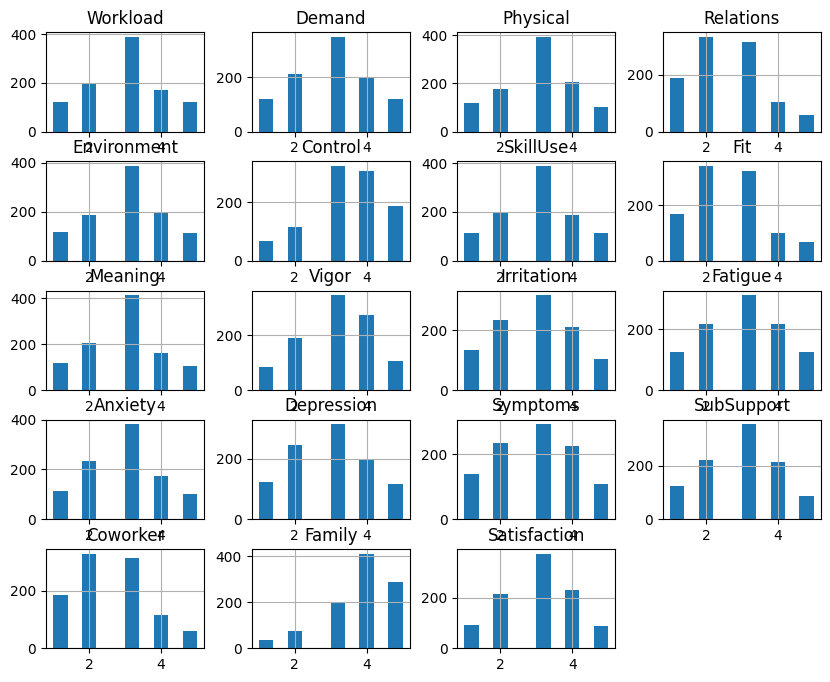

In [4]:
# ヒストグラム
import matplotlib.pyplot as plt

df.hist(figsize=(10, 8))
plt.show()

In [5]:
# 歪度 (Skewness)
df.skew()

Workload        0.060502
Demand          0.029112
Physical       -0.056649
Relations       0.462205
Environment    -0.023673
Control        -0.394428
SkillUse        0.013721
Fit             0.473751
Meaning         0.074145
Vigor          -0.158136
Irritation      0.047683
Fatigue        -0.001923
Anxiety         0.115862
Depression      0.086708
Symptoms        0.025554
SubSupport     -0.000167
Coworker        0.426962
Family         -0.834118
Satisfaction   -0.029334
dtype: float64

In [6]:
# 尖度 (Kurtosis)
df.kurtosis()

Workload       -0.620072
Demand         -0.738693
Physical       -0.572837
Relations      -0.306564
Environment    -0.610813
Control        -0.442485
SkillUse       -0.599264
Fit            -0.264038
Meaning        -0.485134
Vigor          -0.604159
Irritation     -0.813611
Fatigue        -0.852983
Anxiety        -0.559443
Depression     -0.817315
Symptoms       -0.896705
SubSupport     -0.669760
Coworker       -0.389365
Family          0.278626
Satisfaction   -0.552534
dtype: float64

In [7]:
# 相関係数
df_corr = df.corr(method='spearman')

df_corr

,Workload,Demand,Physical,Relations,Environment,Control,SkillUse,Fit,Meaning,Vigor,Irritation,Fatigue,Anxiety,Depression,Symptoms,SubSupport,Coworker,Family,Satisfaction
Workload,1.000000,0.690770,0.035855,-0.031554,0.005902,-0.040503,0.010405,0.049297,-0.042837,0.079652,0.393734,0.339190,0.150698,0.158134,0.227721,-0.011620,-0.041032,0.035779,0.007765
Demand,0.690770,1.000000,0.331575,-0.008804,0.045504,-0.036171,0.023734,-0.025301,-0.004250,0.128043,0.548851,0.538471,0.292120,0.266068,0.325909,0.002273,-0.044308,0.060362,0.014634
Physical,0.035855,0.331575,1.000000,-0.002857,0.041787,0.035120,0.037638,-0.061728,0.049822,0.169042,0.281724,0.459819,0.246893,0.261617,0.279435,0.007884,-0.014090,0.056348,0.082865
Relations,-0.031554,-0.008804,-0.002857,1.000000,0.000941,-0.050324,-0.003475,-0.013093,-0.071388,-0.063036,0.146675,-0.007425,0.180711,0.087861,0.045092,0.035993,0.030898,0.022715,0.119948
Environment,0.005902,0.045504,0.041787,0.000941,1.000000,-0.005317,-0.026929,0.004917,-0.043329,0.056510,0.063372,0.197894,0.104400,0.078138,0.077423,0.021416,-0.013097,0.003775,-0.020598
Control,-0.040503,-0.036171,0.035120,-0.050324,-0.005317,1.000000,0.025875,-0.018155,0.007455,0.306524,-0.045988,-0.052843,-0.008056,-0.022599,-0.035745,-0.005269,0.048475,-0.044663,0.195725
SkillUse,0.010405,0.023734,0.037638,-0.003475,-0.026929,0.025875,1.000000,0.016072,0.032860,0.303339,0.044848,0.054937,0.005898,0.044678,0.062367,0.076857,-0.006398,0.026631,0.138381
Fit,0.049297,-0.025301,-0.061728,-0.013093,0.004917,-0.018155,0.016072,1.000000,-0.012149,-0.004731,-0.032508,0.022030,0.006247,0.009975,-0.007005,-0.026857,0.011702,0.008723,0.214014
Meaning,-0.042837,-0.004250,0.049822,-0.071388,-0.043329,0.007455,0.032860,-0.012149,1.000000,0.243573,-0.028316,-0.032570,0.002650,-0.057158,-0.037644,-0.038545,-0.015614,-0.034765,0.243264
Vigor,0.079652,0.128043,0.169042,-0.063036,0.056510,0.306524,0.303339,-0.004731,0.243573,1.000000,0.142382,0.274943,0.149690,0.184265,0.142930,0.129665,0.077257,-0.001674,0.412474


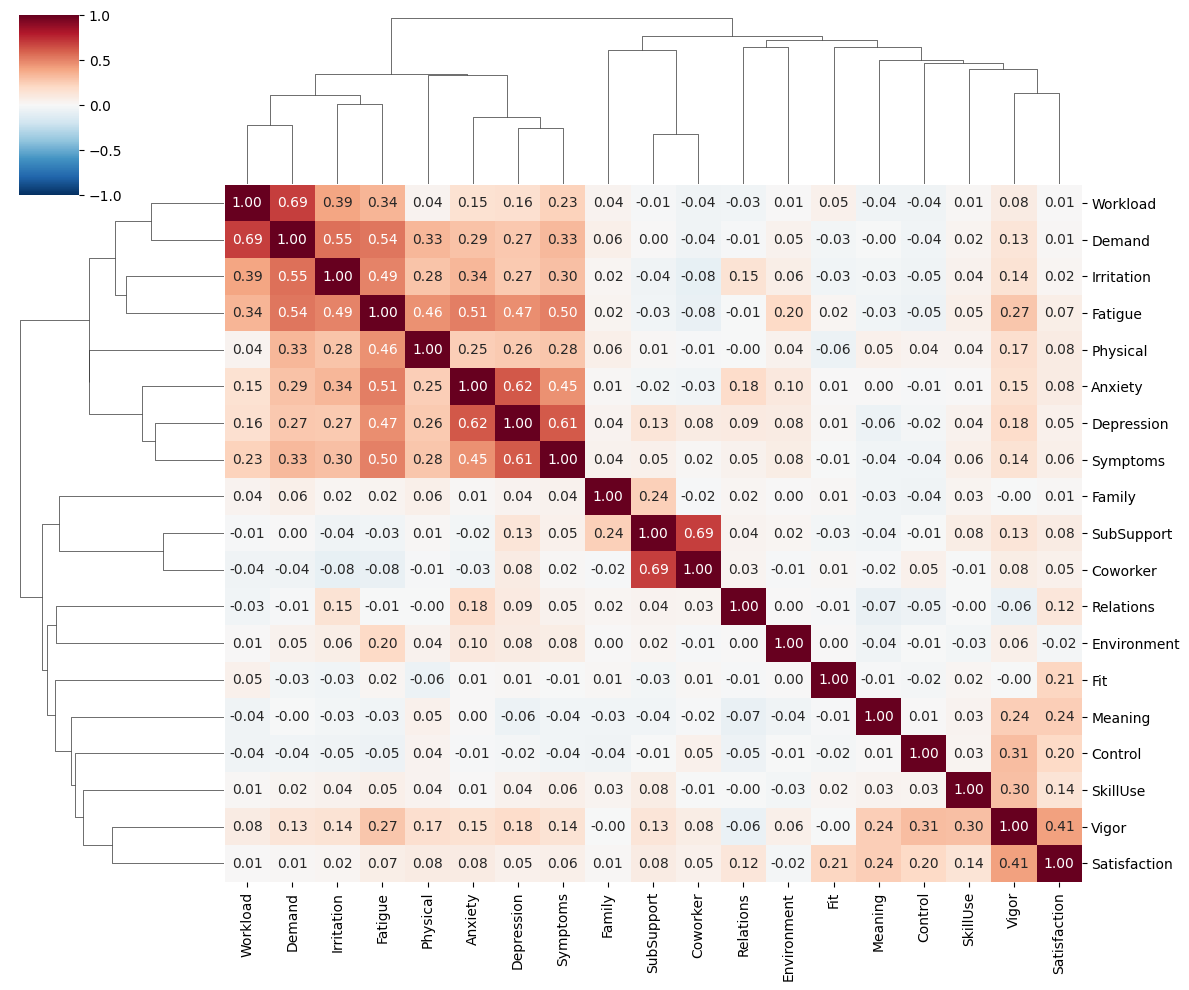

In [8]:
# クラスターマップ

import seaborn as sns

corr = df.corr(method='spearman') # 相関行列の生成

sns.clustermap(
    corr,
    cmap='RdBu_r',
    center=0,
    annot=True,    
    fmt=".2f",
    figsize=(12,10),
    vmin=-1,
    vmax=1
)

In [9]:
# 正規性検定 Shapiro-Wilk検定

from scipy.stats import shapiro

for col in df.columns: # 全列を順に処理
    stat, p = shapiro(df[col]) # shapiro()の戻り値 : ShapiroResult(statistic, pvalue)

    print(
        f"{col:<15}: "
        f"stat={stat:<10.4f}"
        f"p={p:<10.4f}"
        f"正規性棄却={p < 0.05}"
    )

Workload       : stat=0.9104    p=0.0000    正規性棄却=True
Demand         : stat=0.9151    p=0.0000    正規性棄却=True
Physical       : stat=0.9111    p=0.0000    正規性棄却=True
Relations      : stat=0.8958    p=0.0000    正規性棄却=True
Environment    : stat=0.9120    p=0.0000    正規性棄却=True
Control        : stat=0.9006    p=0.0000    正規性棄却=True
SkillUse       : stat=0.9123    p=0.0000    正規性棄却=True
Fit            : stat=0.8955    p=0.0000    正規性棄却=True
Meaning        : stat=0.9078    p=0.0000    正規性棄却=True
Vigor          : stat=0.9147    p=0.0000    正規性棄却=True
Irritation     : stat=0.9163    p=0.0000    正規性棄却=True
Fatigue        : stat=0.9158    p=0.0000    正規性棄却=True
Anxiety        : stat=0.9126    p=0.0000    正規性棄却=True
Depression     : stat=0.9159    p=0.0000    正規性棄却=True
Symptoms       : stat=0.9155    p=0.0000    正規性棄却=True
SubSupport     : stat=0.9159    p=0.0000    正規性棄却=True
Coworker       : stat=0.8992    p=0.0000    正規性棄却=True
Family         : stat=0.8542    p=0.0000    正規性棄却=True
Satisfacti


因果順序の出力
[10, 11, 1, 0, 13, 14, 12, 2, 6, 18, 9, 4, 17, 16, 7, 3, 15, 8, 5]
['Irritation', 'Fatigue', 'Demand', 'Workload', 'Depression', 'Symptoms', 'Anxiety', 'Physical', 'SkillUse', 'Satisfaction', 'Vigor', 'Environment', 'Family', 'Coworker', 'Fit', 'Relations', 'SubSupport', 'Meaning', 'Control']

Adjacency Matrix
【列要素→行要素】の推定係数
              Workload    Demand  Physical  Relations  Environment  Control  \
Workload      0.000000  0.690429       0.0        0.0          0.0      0.0   
Demand        0.000000  0.000000       0.0        0.0          0.0      0.0   
Physical     -0.354747  0.374572       0.0        0.0          0.0      0.0   
Relations     0.000000 -0.091996       0.0        0.0          0.0      0.0   
Environment   0.000000  0.000000       0.0        0.0          0.0      0.0   
Control       0.000000  0.000000       0.0        0.0          0.0      0.0   
SkillUse      0.000000  0.000000       0.0        0.0          0.0      0.0   
Fit           0.000000  0.000000

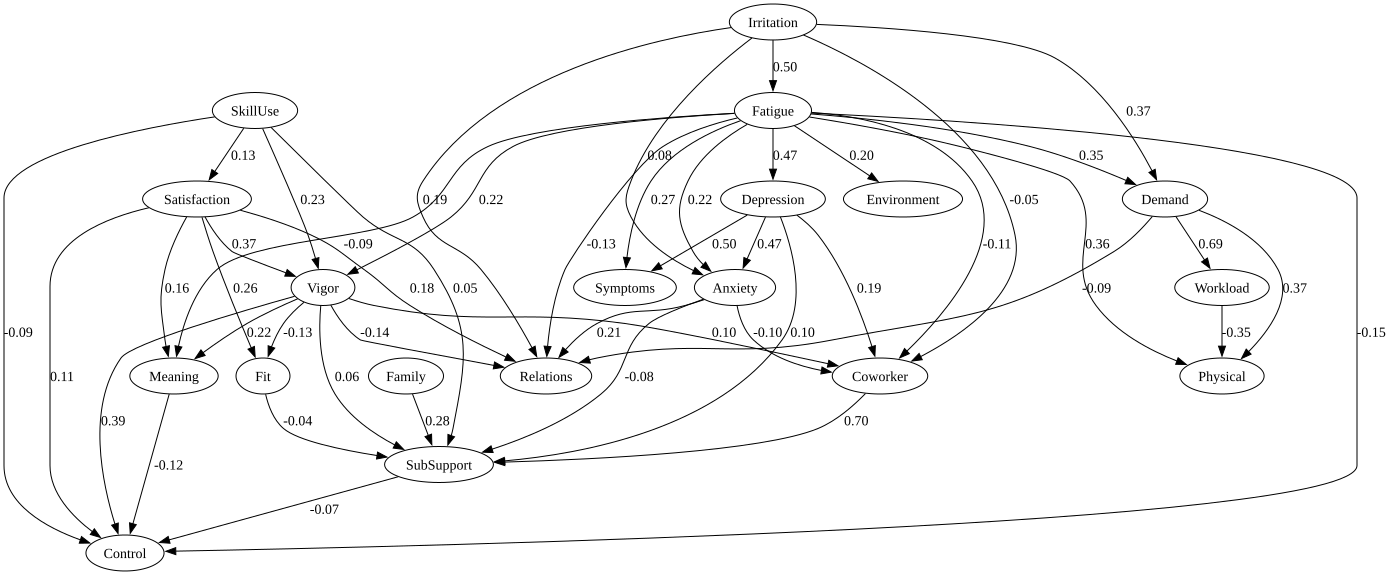

'causal_graph_stress_check_dummy.png'

In [10]:
# 因果推論の実行

"""
DirectLiNGAM
   │
   ├─ fit()
   ├─ bootstrap()
   │      │
   │      └─ BootstrapResult
   │             ├─ get_causal_direction_counts()
   │             ├─ get_probabilities()
   │             ├─ get_total_causal_effects()
   │             └─ get_directed_acyclic_graph_counts()
   │
   ├─ causal_order_
   └─ adjacency_matrix_
"""

#============================================================================================================
#0. インポート
#============================================================================================================
from lingam import DirectLiNGAM
from lingam.utils import make_dot # Graphviz形式の図を作成する

#============================================================================================================
#1. DirectLiNGAM実行
#============================================================================================================
model = DirectLiNGAM()
model.fit(df)

#============================================================================================================
#2. 因果順序の取得
#============================================================================================================
print("\n因果順序の出力")
print(model.causal_order_)

names = [df.columns[i] for i in model.causal_order_]
print(names)

#============================================================================================================
#3. 因果係数(隣接行列)
#============================================================================================================
adj = pd.DataFrame(
    model.adjacency_matrix_,
    index=df.columns,
    columns=df.columns
)
print("\nAdjacency Matrix")
print("【列要素→行要素】の推定係数")
print(adj)

#============================================================================================================
#4. 因果グラフ描画
#============================================================================================================
dot = make_dot(
    model.adjacency_matrix_,
    labels=list(df.columns)
)

print("\n因果グラフ")
display(dot)

# 画像ファイルへ出力
dot.render(f"causal_graph_stress_check_dummy", format="png") 

In [11]:
#============================================================================================================
#5. bootstrap(サンプル変動に対する安定性)
#============================================================================================================
result = model.bootstrap(df.values, n_sampling=1000) 
# bootstrap() : lingamライブラリのDirectLiNGAMクラスのメソッド
# 戻り値 : BootstrapResultオブジェクト

#============================================================================================================
#6. 総因果効果
#============================================================================================================
effects = result.get_total_causal_effects()

# effects
# 戻り値: 
# { 
#     "from":[from(1), from(2), ...], 
#     "to":[to(1), to(2), ...], 
#     "effect":[effect(1), effect(2), ...], 
#     "probability":[probability(1), probability(2), ...] 
# }

# effectsをExcelファイルとして出力
df_effects = pd.DataFrame(effects)

# from, to を列名に変換
df_effects["from"] = df_effects["from"].map(lambda x: df.columns[x])
df_effects["to"] = df_effects["to"].map(lambda x: df.columns[x])

# Excel出力
df_effects.to_excel(
    f"total_causal_effects_dummy.xlsx",
    index=False,
    engine="openpyxl"
)

#============================================================================================================
#7. 出力結果のソート
#============================================================================================================

# (fr, to, eff, prob)のタプルに変換し、昇順にソートする
sorted_effects = sorted(
    zip( 
        effects['from'],
        effects['to'],
        effects['effect'],
        effects['probability']
    ),
    key=lambda x: (abs(x[3]), x[2]),  # abs(x[3])=probabilityの絶対値, x[2]=effects
    reverse=True
)

# 出力形式 【fr -> to eff prob】
for fr, to, eff, prob in sorted_effects:
    print( 
        f"{df.columns[fr]:<20} "
        f" -> " 
        f"{df.columns[to]:<20} "
        f"【effect】 = {eff:6.3f} "
        f"【prob】 = {prob:5.3f}"
    )


因果方向の出現回数
{'from': [9, 9, 18, 11, 11, 15, 1, 16, 10, 1, 11, 18, 11, 13, 11, 11, 16, 12, 10, 13, 0, 11, 18, 14, 10, 11, 13, 9, 9, 6, 18, 9, 10, 15, 9, 13, 14, 18, 3, 1, 11, 11, 11, 8, 9, 5, 2, 1, 13, 3, 12, 11, 6, 13, 1, 13, 14, 15, 4, 12, 12, 3, 15, 3, 15, 7, 1, 9, 3, 15, 15, 13, 3, 9, 10, 14, 7, 10, 12, 6, 2, 0, 12, 7, 17, 0, 11, 11, 6, 11, 10, 11, 10, 14, 2, 2, 16, 2, 16, 12, 17, 2, 7, 0, 0, 0, 9, 10, 1, 10, 12, 15, 3, 8, 1, 6, 12, 7, 3, 0, 14, 13, 14, 6, 4, 13, 3, 10, 0, 18, 18, 7, 7, 10, 2, 18, 9, 2, 7, 9, 15, 16, 4, 1, 15, 1, 16, 17, 8, 7, 0, 5, 16, 14, 12, 12, 16, 8, 0, 2, 15, 4, 5, 1, 9, 7, 15, 2, 10, 10, 2, 18, 16, 14, 16, 6, 17, 0, 13, 12, 10, 4, 14, 5, 7, 3, 14, 2, 9, 3, 8, 0, 18, 14, 8, 2, 4, 6, 5, 2, 10, 0, 1, 4, 10, 6, 4, 6, 13, 6, 8, 12, 2, 14, 5, 2, 4, 4, 18, 12, 6, 9, 18, 4, 18, 13, 16, 17, 12, 9, 17, 3, 8, 1, 15, 3, 7, 11, 5, 3, 1, 14, 12, 4, 14, 8, 15, 14, 8, 5, 0, 4, 13, 5, 15, 6, 16, 9, 5, 4, 15, 16, 6, 18, 17, 3, 1, 13, 13, 2, 12, 13, 16, 16, 18, 6, 3, 17, 9, 1, 8

In [12]:
#============================================================================================================
#8. 誤差独立性検定
#============================================================================================================
# 引数に指定するのは、DirectLiNGAMの学習に使用した元の観測データ

p_values = model.get_error_independence_p_values(df) 

print(p_values)

[[0.00000000e+00 2.40112877e-02 1.61563594e-02 1.88300642e-01
  8.90673153e-01 5.43102865e-01 7.72420670e-01 3.95051527e-01
  5.37363125e-01 8.52187054e-01 2.39004449e-01 5.50974940e-02
  8.42053001e-01 5.54872645e-01 4.57417495e-01 7.98634800e-01
  7.64690154e-01 4.71288191e-01 2.27137437e-01]
 [2.40112877e-02 0.00000000e+00 4.98378567e-01 2.80269587e-01
  7.62159226e-01 5.26913840e-01 1.69938287e-02 8.21413072e-01
  7.95354461e-01 3.59349148e-01 1.18687193e-04 4.02107575e-03
  1.01849946e-01 1.10731148e-01 2.81252433e-01 8.98660518e-01
  5.83481971e-01 1.32752325e-01 8.16672406e-02]
 [1.61563594e-02 4.98378567e-01 0.00000000e+00 4.44752102e-01
  1.64824719e-01 1.95647813e-02 7.22862998e-01 5.86728780e-01
  9.01522872e-04 2.13221330e-01 4.07841600e-02 9.82108885e-03
  5.02246989e-01 2.58764438e-01 6.07839433e-02 5.11184239e-01
  8.27630826e-02 6.38535055e-03 4.18754798e-02]
 [1.88300642e-01 2.80269587e-01 4.44752102e-01 0.00000000e+00
  4.66856336e-01 3.54912243e-02 2.25551033e-01 3.3

In [17]:
# 誤差独立性が棄却されなかった組数
# 総数 361(=19×19)

n_independent = (p_values > 0.05).sum()
n_total = p_values.size

print(
    f"誤差独立性が棄却されなかった組数: "
    f"{n_independent}/{n_total} "
    f"({n_independent / n_total * 100:.1f}%)"
)

誤差独立性が棄却されなかった組数: 270/361 (74.8%)


In [14]:
# 誤差独立性検定
# 各組のp_valueをDataFrameとして作成

import pandas as pd

df_p_values = pd.DataFrame(
    p_values,
    index=df.columns,
    columns=df.columns
)

df_p_values

,Workload,Demand,Physical,Relations,Environment,Control,SkillUse,Fit,Meaning,Vigor,Irritation,Fatigue,Anxiety,Depression,Symptoms,SubSupport,Coworker,Family,Satisfaction
Workload,0.000000,0.024011,0.016156,0.188301,0.890673,0.543103,0.772421,0.395052,0.537363,0.852187,0.239004,5.509749e-02,0.842053,0.554873,4.574175e-01,7.986348e-01,7.646902e-01,0.471288,0.227137
Demand,0.024011,0.000000,0.498379,0.280270,0.762159,0.526914,0.016994,0.821413,0.795354,0.359349,0.000119,4.021076e-03,0.101850,0.110731,2.812524e-01,8.986605e-01,5.834820e-01,0.132752,0.081667
Physical,0.016156,0.498379,0.000000,0.444752,0.164825,0.019565,0.722863,0.586729,0.000902,0.213221,0.040784,9.821089e-03,0.502247,0.258764,6.078394e-02,5.111842e-01,8.276308e-02,0.006385,0.041875
Relations,0.188301,0.280270,0.444752,0.000000,0.466856,0.035491,0.225551,0.339160,0.034674,0.870268,0.520018,2.499558e-01,0.770341,0.164533,8.401810e-02,8.072040e-01,2.378081e-01,0.525767,0.598284
Environment,0.890673,0.762159,0.164825,0.466856,0.000000,0.108709,0.556009,0.837917,0.363386,0.041869,0.329408,1.792225e-05,0.669646,0.162226,2.548220e-01,1.375154e-01,9.495423e-01,0.690110,0.518856
Control,0.543103,0.526914,0.019565,0.035491,0.108709,0.000000,0.049225,0.378248,0.217762,0.009255,0.944463,6.597629e-01,0.728399,0.432154,2.527347e-01,2.119281e-02,3.929163e-01,0.435599,0.037504
SkillUse,0.772421,0.016994,0.722863,0.225551,0.556009,0.049225,0.000000,0.887422,0.547394,0.082632,0.169271,8.958571e-01,0.417839,0.916843,3.065222e-01,3.840489e-03,7.515967e-01,0.635348,0.806835
Fit,0.395052,0.821413,0.586729,0.339160,0.837917,0.378248,0.887422,0.000000,0.529930,0.187429,0.939563,5.943508e-02,0.678512,0.510933,9.284424e-01,1.277941e-01,4.906208e-01,0.628847,0.004828
Meaning,0.537363,0.795354,0.000902,0.034674,0.363386,0.217762,0.547394,0.529930,0.000000,0.408674,0.304732,6.679304e-01,0.136574,0.539588,9.194949e-02,4.483824e-01,6.224090e-01,0.945803,0.171454
Vigor,0.852187,0.359349,0.213221,0.870268,0.041869,0.009255,0.082632,0.187429,0.408674,0.000000,0.011031,5.066161e-02,0.552861,0.686927,2.929652e-01,8.319772e-04,5.249669e-01,0.410380,0.349233


In [15]:
#============================================================================================================
#9. 結果の出力
#============================================================================================================
sorted_effects_pvalue = sorted(
    sorted_effects,
    key=lambda x: (
        df_p_values.loc[
            df.columns[x[0]], # sorted_effectsのindex[0] → from変数名
            df.columns[x[1]]  # sorted_effectsのindex[1] → to変数名
        ] <= 0.05
    )
)

for fr, to, eff, prob in sorted_effects_pvalue:

    src = df.columns[fr]
    dst = df.columns[to]

    p_val = df_p_values.loc[src, dst]
    corr  = df_corr.loc[src, dst]

    print(
        f"{src:<20} -> {dst:<20} "
        f"【effect】={eff:6.3f} "
        f"【ρ】={corr:6.3f} "
        f"【prob】={prob:5.3f} "
        f"【p_value】={p_val:7.5f} "
        f"【p>0.05】={p_val > 0.05}"
    )

Vigor                -> Meaning              【effect】= 0.256 【ρ】= 0.244 【prob】=0.920 【p_value】=0.40867 【p>0.05】=True
Fatigue              -> Control              【effect】=-0.070 【ρ】=-0.053 【prob】=0.920 【p_value】=0.65976 【p>0.05】=True
Satisfaction         -> Meaning              【effect】= 0.206 【ρ】= 0.243 【prob】=0.910 【p_value】=0.17145 【p>0.05】=True
Fatigue              -> Meaning              【effect】=-0.035 【ρ】=-0.033 【prob】=0.890 【p_value】=0.66793 【p>0.05】=True
Depression           -> Meaning              【effect】=-0.035 【ρ】=-0.057 【prob】=0.830 【p_value】=0.53959 【p>0.05】=True
Depression           -> Control              【effect】=-0.008 【ρ】=-0.023 【prob】=0.810 【p_value】=0.43215 【p>0.05】=True
Coworker             -> Family               【effect】=-0.028 【ρ】=-0.016 【prob】=0.760 【p_value】=0.51357 【p>0.05】=True
Demand               -> Physical             【effect】= 0.236 【ρ】= 0.332 【prob】=0.750 【p_value】=0.49838 【p>0.05】=True
Irritation           -> Relations            【effect】= 0.139 【ρ】

In [18]:
# 誤差独立性が棄却されなかった組数
# 総数 342(=19×18)

count_p_gt_005 = sum(
    df_p_values.loc[df.columns[fr], df.columns[to]] > 0.05
    for fr, to, _, _ in sorted_effects
)

# 総組数
total_count = len(sorted_effects)

print(
    f"誤差独立性が棄却されなかった組数: "
    f"{count_p_gt_005}/{total_count} "
    f"({count_p_gt_005 / total_count * 100:.1f}%)"
)

誤差独立性が棄却されなかった組数: 270/342 (78.9%)
